# 4 · Vision SFT
**Idea:** the same as previous methods, but each example is a picture.

- circle = shirt · square = shoes · triangle = jacket
- red = RD · blue = BL · black = BK · white = WH

(a picture of a red circle) → `FIND shirt color=RD`

The model cannot guess this: the meaning of each shape is the shop's own rule.

## Step 1 · Load a small model that can read pictures

In [67]:
import warnings, random, torch
from transformers import AutoModelForImageTextToText, AutoProcessor

warnings.filterwarnings('ignore')            # hide technical warnings

MODEL = 'Qwen/Qwen3.5-0.8B'                  # the same small model; it can read pictures too
processor = AutoProcessor.from_pretrained(MODEL)   # prepares text and pictures for the model
model = AutoModelForImageTextToText.from_pretrained(MODEL, dtype=torch.bfloat16, device_map='cuda')

Loading weights: 100%|██████████| 473/473 [00:01<00:00, 334.92it/s]


## Step 2 · Create the pictures
Code draws each tag, so the correct command is always known.
24 pictures to learn from (each kind of tag twice), and 6 new pictures to test.

In [68]:
ITEM = {'circle': 'shirt', 'square': 'shoes', 'triangle': 'jacket'}
CODE = {'red': 'RD', 'blue': 'BL', 'black': 'BK', 'white': 'WH'}

# Main definition mapping
print("Main mapping definition to image pictures")
for key, value in ITEM.items():
    print(f'key = {key} -> value = {value}')

print()
print('Color mapping')
for key, value in CODE.items():
    print(f'color = {key} -> code = {value}')

Main mapping definition to image pictures
key = circle -> value = shirt
key = square -> value = shoes
key = triangle -> value = jacket

Color mapping
color = red -> code = RD
color = blue -> code = BL
color = black -> code = BK
color = white -> code = WH


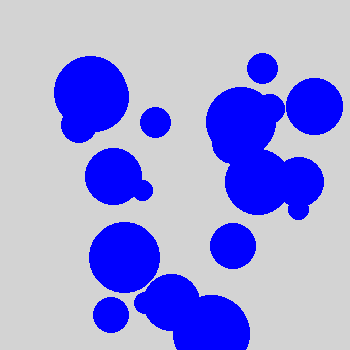

FIND shirt color=BL


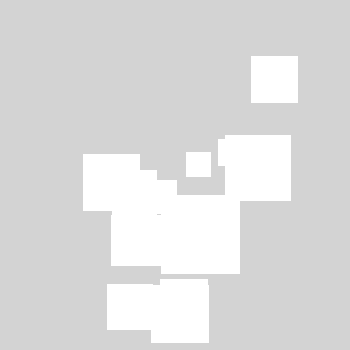

FIND shoes color=WH


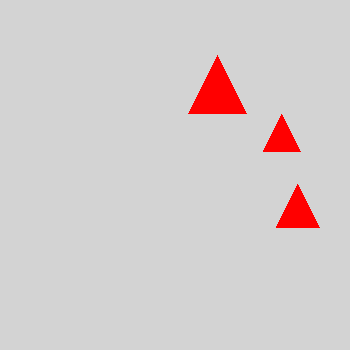

FIND jacket color=RD


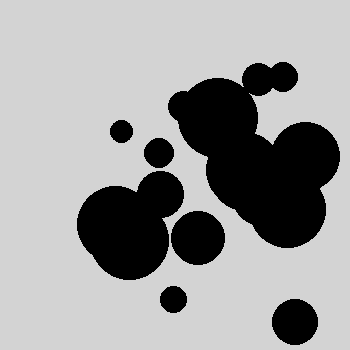

FIND shirt color=BK


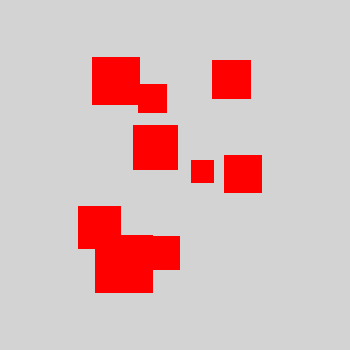

FIND shoes color=RD


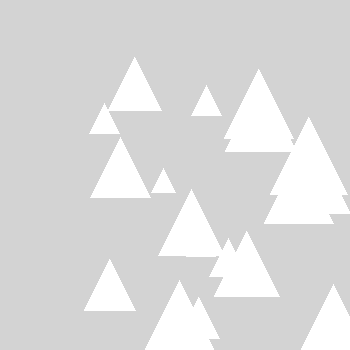

FIND jacket color=WH


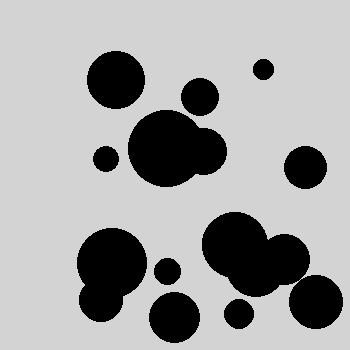

FIND shirt color=BK


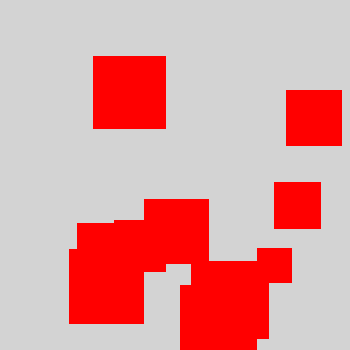

FIND shoes color=RD


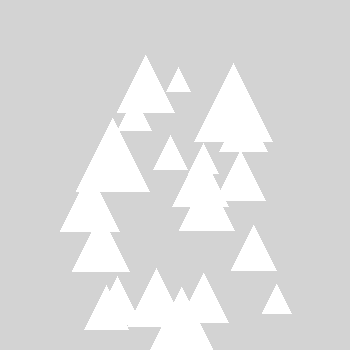

FIND jacket color=WH


In [69]:
from PIL import Image, ImageDraw
import itertools

def draw(shape, color):
    # picture = Image.new('RGB', (128, 128), 'lightgray')
    picture = Image.new('RGB', (350, 350), 'lightgray')
    pen = ImageDraw.Draw(picture)

    # Generate random points and sizes for shapes
    n_items = random.randint(1,20) # random items

    # Generate specific case
    for _ in range(n_items):
        x, y = random.randint(50, 300), random.randint(50, 300)  # random place
        size = random.randint(20, 80) # random size

        if shape == 'circle':
            pen.ellipse([x, y, x + size, y + size], fill=color)

        elif shape == 'square':
            pen.rectangle([x, y, x + size, y + size], fill=color)
        else:
            pen.polygon([(x + size / 2, y), (x, y + size), (x + size, y + size)], fill=color)
    return picture, f'FIND {ITEM[shape]} color={CODE[color]}'

random.seed(0)
TRAIN = []
for i in range(3):
    # generate and append new list
    TRAIN.extend([draw(shape, color) for shape in ITEM for color in CODE for copy in range(2)])

TEST = [draw('circle', 'blue'), draw('square', 'white'), draw('triangle', 'red'), draw('circle', 'black'), draw('square', 'red'), draw('triangle', 'white'), draw('circle', 'black'), draw('square', 'red'), draw('triangle', 'white')]

for picture, command in TEST:
    display(picture)
    print(command)

In [70]:
len(TRAIN), len(TEST)

(72, 9)

In [71]:
TEST

[(<PIL.Image.Image image mode=RGB size=350x350>, 'FIND shirt color=BL'),
 (<PIL.Image.Image image mode=RGB size=350x350>, 'FIND shoes color=WH'),
 (<PIL.Image.Image image mode=RGB size=350x350>, 'FIND jacket color=RD'),
 (<PIL.Image.Image image mode=RGB size=350x350>, 'FIND shirt color=BK'),
 (<PIL.Image.Image image mode=RGB size=350x350>, 'FIND shoes color=RD'),
 (<PIL.Image.Image image mode=RGB size=350x350>, 'FIND jacket color=WH'),
 (<PIL.Image.Image image mode=RGB size=350x350>, 'FIND shirt color=BK'),
 (<PIL.Image.Image image mode=RGB size=350x350>, 'FIND shoes color=RD'),
 (<PIL.Image.Image image mode=RGB size=350x350>, 'FIND jacket color=WH')]

## Step 3 · Ask the model before training


Test case: 1


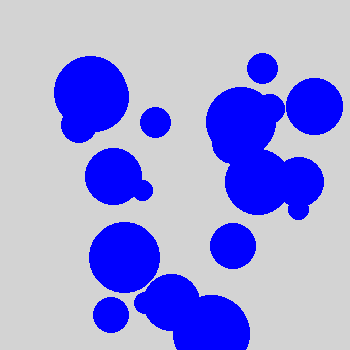

FIND shirt color=BL
wrong: <image_1>    expected: FIND shirt color=BL

Test case: 2


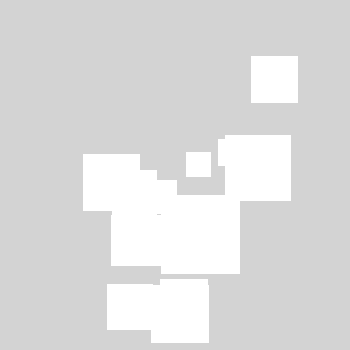

FIND shoes color=WH
wrong: <svg data-bbox="0 0 999 867" data-bbox="0 0 999 867" fill="none" stroke="none" viewBox="0 0 25    expected: FIND shoes color=WH

Test case: 3


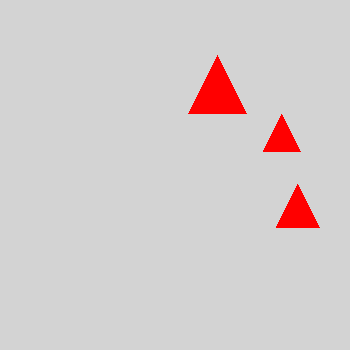

FIND jacket color=RD
wrong: <image1>    expected: FIND jacket color=RD

Test case: 4


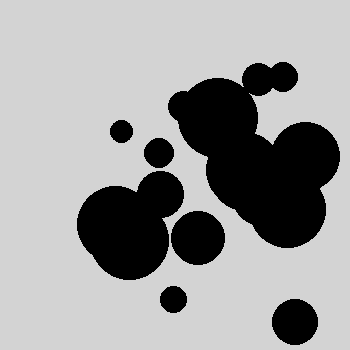

FIND shirt color=BK
wrong: /    expected: FIND shirt color=BK

Test case: 5


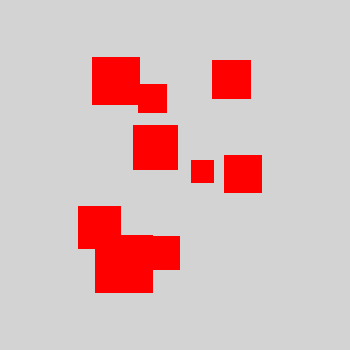

FIND shoes color=RD
wrong: <tag>red</tag>    expected: FIND shoes color=RD

Test case: 6


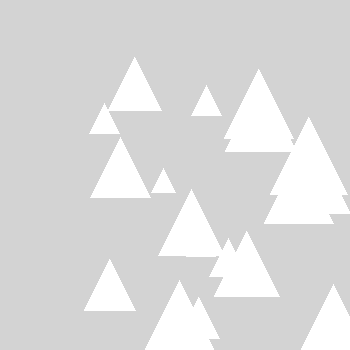

FIND jacket color=WH
wrong: <image:1>    expected: FIND jacket color=WH

Test case: 7


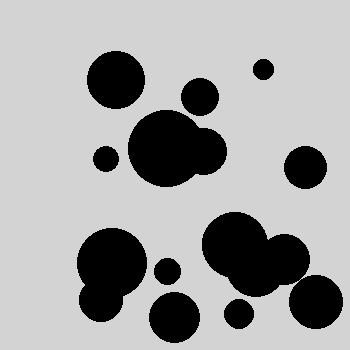

FIND shirt color=BK
wrong: /    expected: FIND shirt color=BK

Test case: 8


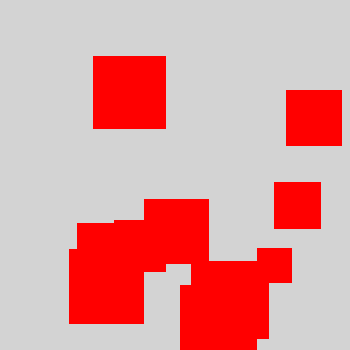

FIND shoes color=RD
wrong: <image_1>    expected: FIND shoes color=RD

Test case: 9


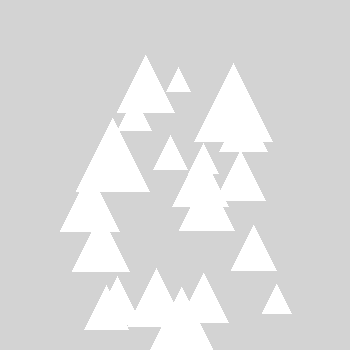

FIND jacket color=WH
wrong: <tag>tree</tag>    expected: FIND jacket color=WH
0 of 9 right


In [72]:
QUESTION = 'Search command for this tag.'

def ask(model, picture):
    chat = [{'role': 'user', 'content': [{'type': 'image'}, {'type': 'text', 'text': QUESTION}]}]
    text = processor.apply_chat_template(chat, add_generation_prompt=True)
    inputs = processor(text=text, images=[picture], return_tensors='pt').to('cuda', torch.bfloat16)
    output = model.generate(**inputs, max_new_tokens=50, do_sample=False)
    answer = output[0][inputs['input_ids'].shape[1]:]  # keep only the new words
    return processor.decode(answer, skip_special_tokens=True).strip()

def test(model):
    model.eval() # answering mode
    right = 0
    ii = 0 # count
    for picture, command in TEST:
        ii +=1
        answer = ask(model, picture)

        # Show the image and case to understand better
        print()
        print(f'Test case: {ii}')
        display(picture)
        print(command)

        if answer == command:
            right += 1
            print('right:', answer)
        else:
            print('wrong:', answer, '   expected:', command)
    print(right, 'of', len(TEST), 'right')

test(model)

## Step 4 · Train
The same as notebook 1, plus an `image` for each example.
The picture is turned into tokens, and then training works just like with text. Watch the `loss` go down.

In [73]:
from datasets import Dataset
from peft import LoraConfig
from trl import SFTTrainer, SFTConfig

data = Dataset.from_list([
    {'image': picture,
     'prompt': [{'role': 'user', 'content': QUESTION}],
     'completion': [{'role': 'assistant', 'content': command}]}
    for picture, command in TRAIN
])

trainer = SFTTrainer(
    model=model,
    processing_class=processor,
    train_dataset=data,
    peft_config=LoraConfig(r=16, lora_alpha=32, target_modules='all-linear'),   # the small add-on
    args=SFTConfig(
        max_length=None,         # never cut the input (it would break the picture)
        num_train_epochs=10,     # each picture is seen 10 times
        learning_rate=1e-4,      # size of each small adjustment
        logging_steps=1,         # print the loss every 3 steps
        save_strategy='no',      # do not save copies to disk
    ),
)
trainer.train()

[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 248046}.


Step,Training Loss
1,7.622224
2,5.080261
3,3.415538
4,2.076568
5,1.192512
6,0.881675
7,0.332846
8,0.167973
9,0.106036
10,0.180312


TrainOutput(global_step=90, training_loss=0.2424423967798551, metrics={'train_runtime': 88.1586, 'train_samples_per_second': 8.167, 'train_steps_per_second': 1.021, 'total_flos': 392826678220800.0, 'train_loss': 0.2424423967798551, 'epoch': 10.0})

## Step 5 · Ask the model after training
The same 6 test pictures. The model never saw them, so right answers mean it learned the rules.

In [76]:
# Remember mapping

# Main definition mapping
print("Main mapping definition to image pictures")
for key, value in ITEM.items():
    print(f'key = {key} -> value = {value}')
    
print()
print('Color mapping')
for key, value in CODE.items():
    print(f'color = {key} -> code = {value}')

Main mapping definition to image pictures
key = circle -> value = shirt
key = square -> value = shoes
key = triangle -> value = jacket

Color mapping
color = red -> code = RD
color = blue -> code = BL
color = black -> code = BK
color = white -> code = WH



Test case: 1


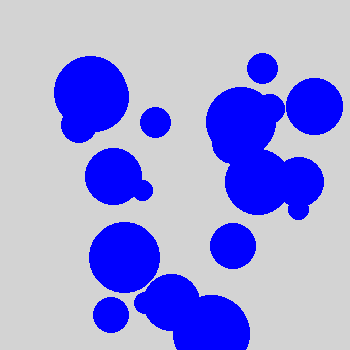

FIND shirt color=BL
right: FIND shirt color=BL

Test case: 2


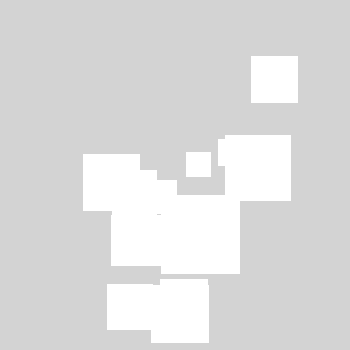

FIND shoes color=WH
right: FIND shoes color=WH

Test case: 3


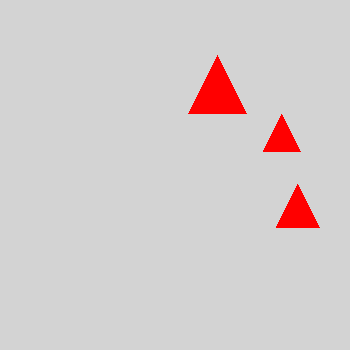

FIND jacket color=RD
right: FIND jacket color=RD

Test case: 4


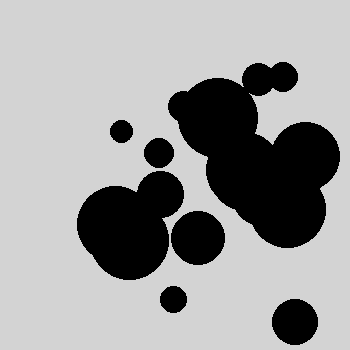

FIND shirt color=BK
right: FIND shirt color=BK

Test case: 5


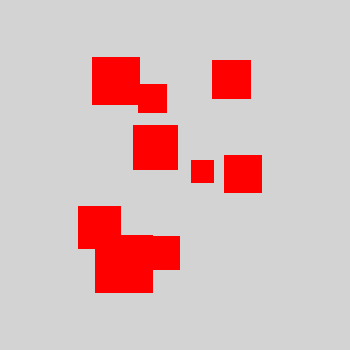

FIND shoes color=RD
right: FIND shoes color=RD

Test case: 6


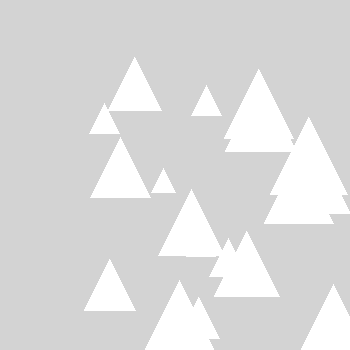

FIND jacket color=WH
right: FIND jacket color=WH

Test case: 7


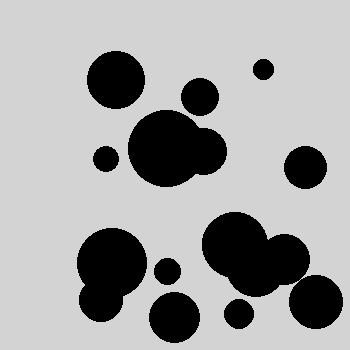

FIND shirt color=BK
right: FIND shirt color=BK

Test case: 8


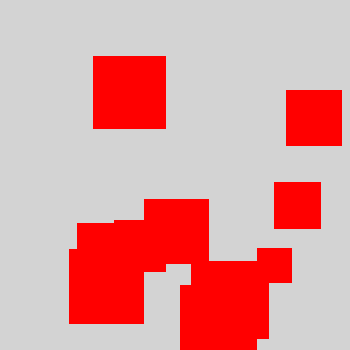

FIND shoes color=RD
right: FIND shoes color=RD

Test case: 9


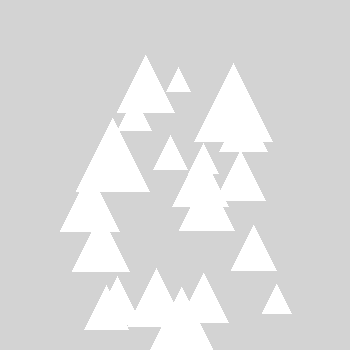

FIND jacket color=WH
right: FIND jacket color=WH
9 of 9 right


In [77]:
test(trainer.model)